### Problem 9 : SCRUB - a student that selectively disobeys its teacher

⏱️ ~40 min · 🧭 Stage 4 (Approximate unlearning), rung 6 · 📄 `resources/papers/03-approximate-unlearning/2023-kurmanji-scrub-towards-unbounded-mu.pdf`

> 🔗 **Building on Problem 8 :** gradient ascent and NegGrad+ had two missing pieces. They had no **reference** - "be
> wrong on Carol" is not what a model that never saw her does - and no **stopping rule** that works without the gold
> standard. Only 1 of 46 configurations passed.

SCRUB (Kurmanji, Triantafillou, Hayes & Triantafillou, NeurIPS 2023) changes the question. Instead of "be wrong on
Carol", it says :

> *"Stay **identical to the original model** on everyone else, and **move away from it** on Carol."*

The original model becomes a frozen **teacher**; a copy of it, the **student**, is trained with two opposing forces.
And SCRUB+R adds the stopping rule : keep a checkpoint after every epoch and **rewind** to the one that is "just forgetful
enough".

![SCRUB](assets/diagrams/06_scrub.png)

> 🟢 **In plain words :** imagine an apprentice who copies a master craftsman. We tell the apprentice : "do everything
> exactly like the master - except, for Carol's digits, deliberately do something *different* from what the master
> would do." Because the apprentice keeps copying the master everywhere else, they don't lose their skill.

> 🔴 **For practitioners :** with `d(x) = KL(p_teacher(x) ‖ p_student(x))` on temperature-softened outputs, SCRUB solves
> `min_w  α·E_{D_r}[d] + γ·E_{D_r}[CE] − E_{D_f}[d]` (paper, Eq. 3), but optimises it as alternating **max-steps**
> (an epoch ascending `d` on D_f) and **min-steps** (an epoch descending on D_r), followed by extra min-steps - the
> GAN-style trick in Algorithm 1. The code is `mul/methods.py → scrub()` : read it, it is ~25 lines.

**TASK :** Run SCRUB on Carol, watch the max/min dance epoch by epoch, use SCRUB+R's rewind, and find out - honestly -
when SCRUB works and when it does not.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import lab, train, methods, audit, nn, viz
viz.style()

def setup(scenario):
    """Original model + gold band + reference models for one lab scenario (Problems 5-6)."""
    Lx = lab.make_lab(scenario)
    sx = Lx.splits()
    orig = train.fit(lab.model_fn, Lx.X_train, Lx.y_train, seed=0, **lab.FIT)
    OUTx = [train.fit(lab.model_fn, Lx.Xr, Lx.yr, seed=s, **lab.FIT) for s in range(100, 112)]
    INx = [train.fit(lab.model_fn, Lx.X_train, Lx.y_train, seed=s, **lab.FIT) for s in range(1, 9)]
    bm, bs = audit.gold_band(OUTx, sx, in_models=INx, mia=False)
    return Lx, sx, orig, OUTx, INx, bm, bs

L, splits, original, OUT, IN, band_mean, band_std = setup("carol")
lo, hi = band_mean["forget_acc"] - 2 * band_std["forget_acc"], band_mean["forget_acc"] + 2 * band_std["forget_acc"]
print(f"gold band for Carol: {lo:.1%} - {hi:.1%}  |  original: {train.accuracy(original, L.Xf, L.yf):.1%}")

gold band for Carol: 53.3% - 72.2%  |  original: 100.0%


#### Step 1 : The teacher - it is simply the original model. Step 2 : the issue - Carol at 100%.

#### Step 3 : Untrain - watch SCRUB epoch by epoch

We record, after every epoch : accuracy on Carol (should fall into the band), accuracy on *unseen* thick-marker digits
(we must not destroy the model's ability to read her *style*), and test accuracy.

In [2]:
# Step 3: SCRUB with per-epoch history
cfg = dict(steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0)
hist = []
def record(student, epoch, kind):
    hist.append(dict(epoch=epoch + 1, kind=kind, carol=train.accuracy(student, L.Xf, L.yf),
                     style=train.accuracy(student, L.X_like_forget, L.y_like_forget),
                     test=train.accuracy(student, L.X_test, L.y_test)))
scrubbed, info = methods.scrub(original, L.Xr, L.yr, L.Xf, history=record, return_checkpoints=True, **cfg)
H = pd.DataFrame(hist)
print(H.round(3).to_string(index=False))

 epoch    kind  carol  style  test
     1 max+min  1.000  0.800 0.980
     2 max+min  0.975  0.788 0.983
     3 max+min  0.950  0.738 0.954
     4 max+min  0.650  0.538 0.980
     5     min  0.775  0.625 0.981
     6     min  0.825  0.688 0.980
     7     min  0.825  0.700 0.980
     8     min  0.825  0.700 0.978


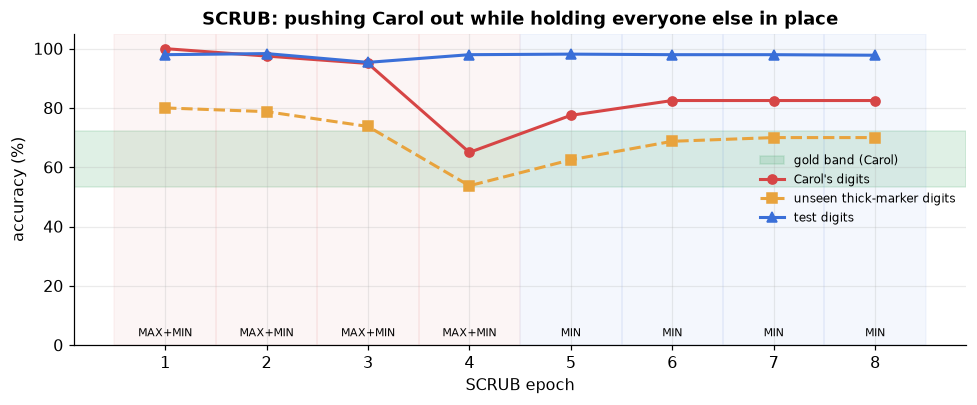

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhspan(100 * lo, 100 * hi, color=viz.RETRAIN, alpha=0.15, label="gold band (Carol)")
ax.plot(H.epoch, 100 * H.carol, "o-", color=viz.FORGET, lw=2, label="Carol's digits")
ax.plot(H.epoch, 100 * H["style"], "s--", color=viz.ACCENT, lw=2, label="unseen thick-marker digits")
ax.plot(H.epoch, 100 * H.test, "^-", color=viz.RETAIN, lw=2, label="test digits")
for e, k in zip(H.epoch, H.kind):
    ax.axvspan(e - 0.5, e + 0.5, color=viz.FORGET if k == "max+min" else viz.RETAIN, alpha=0.05)
    ax.text(e, 3, "MAX+MIN" if k == "max+min" else "MIN", ha="center", fontsize=7.5)
ax.set_xlabel("SCRUB epoch"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 105); ax.legend(fontsize=8, loc="center right")
ax.set_title("SCRUB: pushing Carol out while holding everyone else in place"); plt.tight_layout(); plt.show()

Watch the two lines that matter. The red line (Carol) is pushed down by the **max**-steps, while the blue line (test)
barely moves - the **min**-steps keep the student glued to the teacher on everyone else. That is the teacher reference
doing its job : unlike gradient ascent in Problem 8, the rest of the model does not collapse.

But look at what happens *after* the max-steps stop. Carol drops into the green band at the last max+min epoch - and then,
during the repair-only (MIN) epochs, she **climbs back out**. Copying the teacher on everyone else partly re-teaches the
student what Carol's digits look like : her influence had been *pushed aside*, not removed. This **relapse** is the
same phenomenon that makes LLM unlearning so fragile (Problem 16), and it is exactly why a rewind is needed.

#### SCRUB+R : the stopping rule that does not need the gold standard

In production we cannot compute the gold band. SCRUB+R (paper, §3.2) estimates the right forgetting level from data we
*do* have : a held-out set from the **same distribution** as the forget set - here, unseen thick-marker digits. The final
SCRUB model's error on that set is the reference ("how wrong should a model be on data like Carol's that it never saw?"),
and we rewind to the checkpoint whose error on Carol is closest to it.

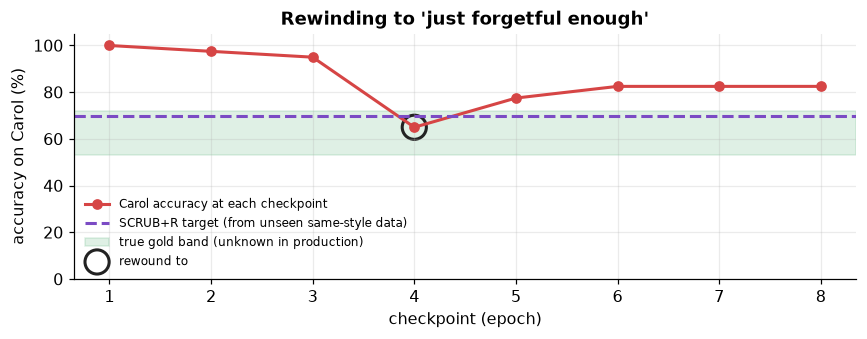

In [4]:
# SCRUB+R: rewind to the checkpoint whose error on Carol best matches the error on unseen same-style data
rewound, rinfo = methods.scrub_rewind(original, L.Xr, L.yr, L.Xf, L.yf, L.X_like_forget, L.y_like_forget, **cfg)
errs = rinfo["forget_error_per_checkpoint"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(1, len(errs) + 1), [100 * (1 - e) for e in errs], "o-", color=viz.FORGET, lw=2, label="Carol accuracy at each checkpoint")
ax.axhline(100 * (1 - rinfo["reference_error"]), color=viz.METHOD, ls="--", lw=2, label="SCRUB+R target (from unseen same-style data)")
ax.axhspan(100 * lo, 100 * hi, color=viz.RETRAIN, alpha=0.15, label="true gold band (unknown in production)")
ax.scatter([rinfo["chosen_checkpoint"] + 1], [100 * (1 - errs[rinfo["chosen_checkpoint"]])], s=250, facecolors="none", edgecolors=viz.INK, lw=2, label="rewound to")
ax.set_xlabel("checkpoint (epoch)"); ax.set_ylabel("accuracy on Carol (%)"); ax.legend(fontsize=8); ax.set_ylim(0, 105)
ax.set_title("Rewinding to 'just forgetful enough'"); plt.tight_layout(); plt.show()

#### Step 4 : Show the result, and Step 5 : Prove it

In [5]:
# Step 4 + 5: full audit of SCRUB and SCRUB+R against the gold band
models = {"original": original, "retrain": train.fit(lab.model_fn, L.Xr, L.yr, seed=999, **lab.FIT),
          "SCRUB": scrubbed, "SCRUB+R": rewound}
table = audit.audit(models, splits, OUT, in_models=IN, mia=False)
print(table[["forget_acc", "test_acc", "ulira"]].join(audit.gate(table, band_mean, band_std)).round(3).to_string())

          forget_acc  test_acc  ulira FORGET PRIVACY UTILITY verdict
method                                                              
original       1.000     0.980  0.950      x       x      ok    FAIL
retrain        0.625     0.980  0.075     ok      ok      ok    PASS
SCRUB          0.825     0.978  0.275      x       x      ok    FAIL
SCRUB+R        0.650     0.980  0.125     ok      ok      ok    PASS


For this configuration, plain SCRUB relapses and fails FORGET and PRIVACY (Carol is partly back); the rewind picks the
checkpoint from just before the relapse, and it passes. **But is that the rule or the exception ?** Problem 8 taught us
to check.

#### The honest scoreboard : how often does each method pass ?

We sweep 16 reasonable SCRUB configurations (learning rate, forget batch size, temperature, number of max/min
epochs) with and without the rewind, plus the Problem 8 baselines, on two very different requests : **Carol** (a
memorised individual) and **class** (every digit 3 - like removing one person from a face-ID model).

In [6]:
# The scoreboard: fraction of configurations that pass the full gate, per method and scenario
def sweep(Lx, sx, orig, OUTx, INx, bm, bs):
    C = {}
    for lr, fb, T, (st, ms) in itertools.product([5e-4, 1e-3], [8, 16], [1.0, 4.0], [(8, 4), (10, 6)]):
        kw = dict(steps=st, max_steps=ms, lr=lr, forget_batch_size=fb, T=T)
        C[f"SCRUB|{lr}|{fb}|{T}|{st}"] = methods.scrub(orig, Lx.Xr, Lx.yr, Lx.Xf, **kw)[0]
        C[f"SCRUB+R|{lr}|{fb}|{T}|{st}"] = methods.scrub_rewind(orig, Lx.Xr, Lx.yr, Lx.Xf, Lx.yf, Lx.X_like_forget, Lx.y_like_forget, **kw)[0]
    for a, lr, ep in itertools.product([0.99, 0.995, 0.999], [1e-4, 3e-4, 1e-3], [1, 2, 3, 5]):
        C[f"neggrad+|{a}|{lr}|{ep}"] = methods.neggrad_plus(orig, Lx.Xr, Lx.yr, Lx.Xf, Lx.yf, epochs=ep, alpha=a, lr=lr)[0]
    for lr, ep in itertools.product([1e-4, 3e-4], [3, 4, 5, 6, 8]):
        C[f"gradient_ascent|{lr}|{ep}"] = methods.gradient_ascent(orig, Lx.Xf, Lx.yf, epochs=ep, lr=lr)[0]
    t = audit.audit(C, sx, OUTx, in_models=INx, mia=False)
    g = audit.gate(t, bm, bs)
    t = t.join(g)
    t["family"] = [i.split("|")[0] for i in t.index]
    return t

results = {"carol": sweep(L, splits, original, OUT, IN, band_mean, band_std)}
Lc, sc, oc, OUTc, INc, bmc, bsc = setup("class")
results["class"] = sweep(Lc, sc, oc, OUTc, INc, bmc, bsc)

score = pd.DataFrame({scen: r.groupby("family").apply(lambda d: f"{(d.verdict == 'PASS').sum()} / {len(d)}")
                      for scen, r in results.items()})
print(score.loc[["gradient_ascent", "neggrad+", "SCRUB", "SCRUB+R"]])

                  carol    class
family                          
gradient_ascent  0 / 10   0 / 10
neggrad+         1 / 36  19 / 36
SCRUB            0 / 16  10 / 16
SCRUB+R          1 / 16   8 / 16


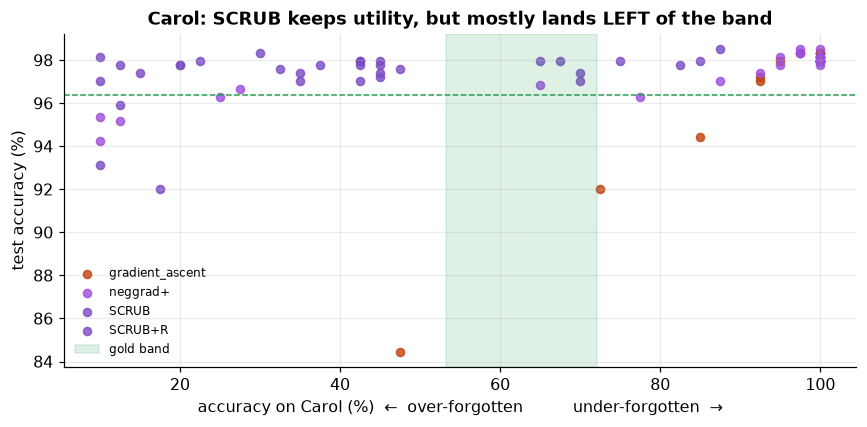

In [7]:
# Where do the failures land ? (Carol)
r = results["carol"]
fig, ax = plt.subplots(figsize=(8, 4))
for fam in ["gradient_ascent", "neggrad+", "SCRUB", "SCRUB+R"]:
    d = r[r.family == fam]
    ax.scatter(100 * d.forget_acc, 100 * d.test_acc, s=28, color=viz.color_for(fam), label=fam, alpha=0.8)
ax.axvspan(100 * lo, 100 * hi, color=viz.RETRAIN, alpha=0.15, label="gold band")
ax.axhline(100 * (band_mean["test_acc"] - 0.02), color=viz.RETRAIN, ls="--", lw=1)
ax.set_xlabel("accuracy on Carol (%)  ←  over-forgotten          under-forgotten  →"); ax.set_ylabel("test accuracy (%)")
ax.legend(fontsize=8); ax.set_title("Carol: SCRUB keeps utility, but mostly lands LEFT of the band"); plt.tight_layout(); plt.show()

**Read that scoreboard again** - it is the most important table in this stage.

- On **class** forgetting, every method with an *anchor* does well : NegGrad+ and SCRUB both pass in roughly half to
  two-thirds of configurations, utility intact. The target is unambiguous (a model that never saw a 3 never says 3).
  Gradient ascent, with no anchor, never passes.
- On **Carol**, almost nothing passes. SCRUB's dots sit high (utility is fine - the teacher reference works) but mostly
  **left of the band** : it over-forgets. "Move away from the teacher" has no notion of *how far* is far enough, and
  Carol's target is not 0% but ~60%. The configurations that do not over-forget tend to *relapse* (above). The rewind
  rescues only the occasional run.
- The privacy test (U-LiRA) does not catch over-forgetting - an over-forgotten model looks *less* like a member, not more.
  Only the **gold band check** catches it. That is why the audit needs several tests, not one.

This matches what the paper itself reports (SCRUB+R exists precisely because over-forgetting is a membership signal)
and what the NeurIPS 2023 unlearning competition found more broadly : approximate methods are **sensitive to the request
type and to their hyper-parameters**, and there is no configuration that is safe to run blind.

----
#### OUTCOME :

| | Gradient ascent (P8) | NegGrad+ (P8) | SCRUB | SCRUB+R |
|---|---|---|---|---|
| Reference for "forgotten" | none ("be wrong") | none | the **teacher** | the teacher + same-style validation data |
| Protects utility? | ❌ | partly | ✅ | ✅ |
| Stopping rule without the gold band? | ❌ | ❌ | ❌ | ✅ (rewind) |
| Class forgetting | never passes | passes about half the time | passes ~60% of the time | passes ~half the time |
| Memorised individual (Carol) | never passes | 1 setting in 36 | never - **over-forgets or relapses** | 1 setting in 16 |

#### Key Takeaways :

- SCRUB uses the original model as a **teacher** : copy it on D_r, diverge from it on D_f.
- Alternating **max/min** epochs keeps utility intact where gradient ascent collapsed.
- **SCRUB+R** rewinds to a checkpoint whose forget error matches same-style held-out data - a stopping rule you can use
  in production.
- Pushed-aside knowledge can **relapse** during repair epochs - the rewind exists for this.
- Anchored methods handle **class-level** forgetting well; on memorised **individuals** SCRUB over-forgets or relapses,
  and only the gold-band check reveals it.

#### TASK :
1. SCRUB+R's reference is the *final* model's error on unseen same-style data - but SCRUB also degrades that set. Change
   the reference to the **original** model's error on `L.X_like_forget` minus a margin, re-run the sweep, and compare the
   pass rate. Is your rule still something you could compute in production?
2. Save a checkpoint every **half** epoch instead of every epoch (hint: split the max and min phases). Does a finer
   rewind pass more often on Carol?
3. Run the sweep on `lab.make_lab("random")`. Which methods pass when the original model is *already* inside the band?
4. Read Section 3.2 and Appendix of the SCRUB paper in `resources/`. How do the authors choose between SCRUB and SCRUB+R
   for different applications (bias removal, confusion resolution, privacy)?

#### ❓ Open question → Problem 10
SCRUB's max-step says "be *different* from the teacher on Carol" - but different in which direction ? **What if we gave
the student an explicit target for Carol instead - a second teacher that knows *nothing* - and copied it in a single,
fast epoch?** That is the Bad Teacher.